<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/susy_field_theory/susyft_ch03_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Supersymmetric Field Theory* — `susyft_ch03_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# SUSYFT CH03 Figures
Ch 3: Chiral Superfields, Wess-Zumino Model, Non-Renormalisation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
GOLD='#e8b84b'; BLUE='#7ec8e3'; PURP='#c792ea'
GREEN='#90ee90'; RED='#e07070'; ORAN='#e8a838'; TEAL='#2ec4b6'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':GOLD,'lines.linewidth':2.2,'axes.linewidth':1.2,'figure.dpi':110,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()
print('Setup — SUSYFT ch03 figures.')


Setup — SUSYFT ch03 figures.


  saved -> figures/ch03/fig01_superspace.png


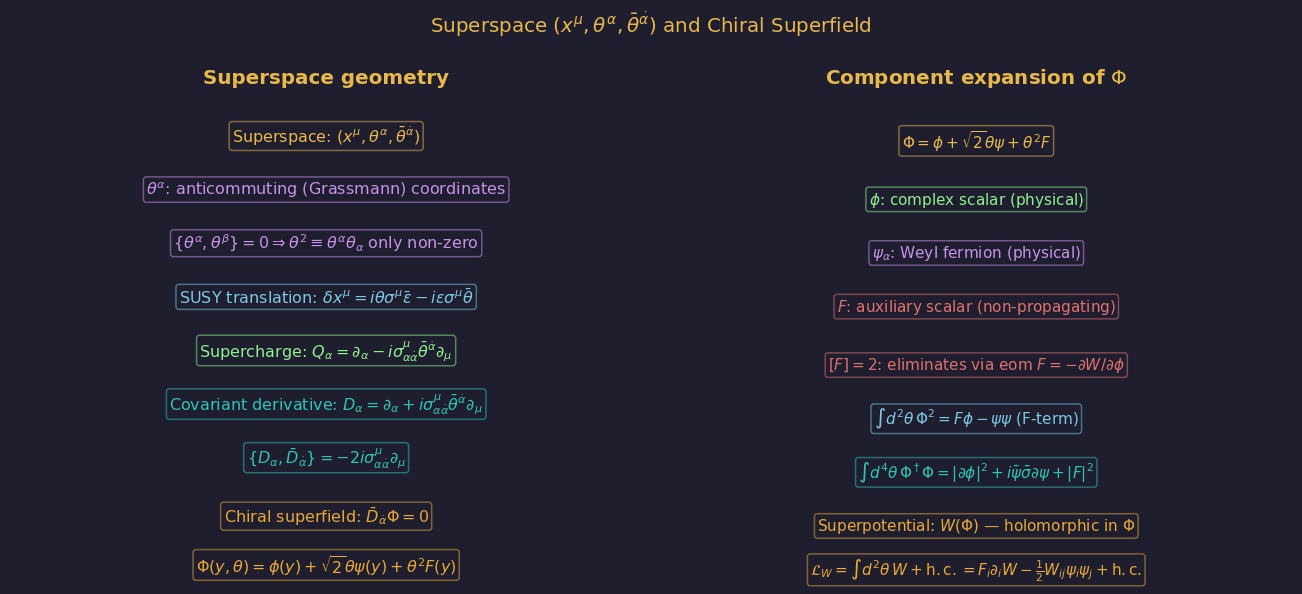

In [2]:
# Superspace coordinates and chiral superfield
fig, axes = plt.subplots(1,2,figsize=(12,5.5))
fig.suptitle(r'Superspace $(x^\mu,\theta^\alpha,\bar\theta^{\dot\alpha})$ and Chiral Superfield', color=GOLD,fontsize=13)

ax=axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title('Superspace geometry',color=GOLD)
items=[
  (0.5,0.91,r'Superspace: $(x^\mu, \theta^\alpha, \bar\theta^{\dot\alpha})$',GOLD),
  (0.5,0.80,r'$\theta^\alpha$: anticommuting (Grassmann) coordinates',PURP),
  (0.5,0.69,r'$\{\theta^\alpha,\theta^\beta\}=0 \Rightarrow \theta^2\equiv\theta^\alpha\theta_\alpha$ only non-zero',PURP),
  (0.5,0.58,r'SUSY translation: $\delta x^\mu = i\theta\sigma^\mu\bar\epsilon - i\epsilon\sigma^\mu\bar\theta$',BLUE),
  (0.5,0.47,r'Supercharge: $Q_\alpha = \partial_\alpha - i\sigma^\mu_{\alpha\dot\alpha}\bar\theta^{\dot\alpha}\partial_\mu$',GREEN),
  (0.5,0.36,r'Covariant derivative: $D_\alpha = \partial_\alpha + i\sigma^\mu_{\alpha\dot\alpha}\bar\theta^{\dot\alpha}\partial_\mu$',TEAL),
  (0.5,0.25,r'$\{D_\alpha, \bar D_{\dot\alpha}\} = -2i\sigma^\mu_{\alpha\dot\alpha}\partial_\mu$',TEAL),
  (0.5,0.13,r'Chiral superfield: $\bar D_{\dot\alpha}\Phi=0$',ORAN),
  (0.5,0.03,r'$\Phi(y,\theta) = \phi(y)+\sqrt{2}\theta\psi(y)+\theta^2 F(y)$',ORAN),
]
for x_,y_,txt,col in items:
    ax.text(x_,y_,txt,ha='center',va='center',fontsize=10.5,color=col,
            transform=ax.transAxes,bbox=dict(boxstyle='round,pad=0.18',fc=BG,ec=col,alpha=0.5))

ax2=axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title(r'Component expansion of $\Phi$',color=GOLD)
comps=[
  (0.5,0.90,r'$\Phi = \phi + \sqrt{2}\theta\psi + \theta^2 F$',GOLD),
  (0.5,0.78,r'$\phi$: complex scalar (physical)',GREEN),
  (0.5,0.67,r'$\psi_\alpha$: Weyl fermion (physical)',PURP),
  (0.5,0.56,r'$F$: auxiliary scalar (non-propagating)',RED),
  (0.5,0.44,r'$[F]=2$: eliminates via eom $F=-\partial W/\partial\phi$',RED),
  (0.5,0.33,r'$\int d^2\theta\,\Phi^2 = F\phi - \psi\psi$ (F-term)',BLUE),
  (0.5,0.22,r'$\int d^4\theta\,\Phi^\dagger\Phi = |\partial\phi|^2+i\bar\psi\bar\sigma\partial\psi+|F|^2$',TEAL),
  (0.5,0.11,r'Superpotential: $W(\Phi)$ — holomorphic in $\Phi$',ORAN),
  (0.5,0.02,r'$\mathcal{L}_{W}=\int d^2\theta\,W + \mathrm{h.c.} = F_i\partial_iW - \frac{1}{2}W_{ij}\psi_i\psi_j+\mathrm{h.c.}$',ORAN),
]
for x_,y_,txt,col in comps:
    ax2.text(x_,y_,txt,ha='center',va='center',fontsize=10,color=col,
             transform=ax2.transAxes,bbox=dict(boxstyle='round,pad=0.18',fc=BG,ec=col,alpha=0.5))
plt.tight_layout()
save('fig01_superspace.png',fig)


  saved -> figures/ch03/fig02_wz_model.png


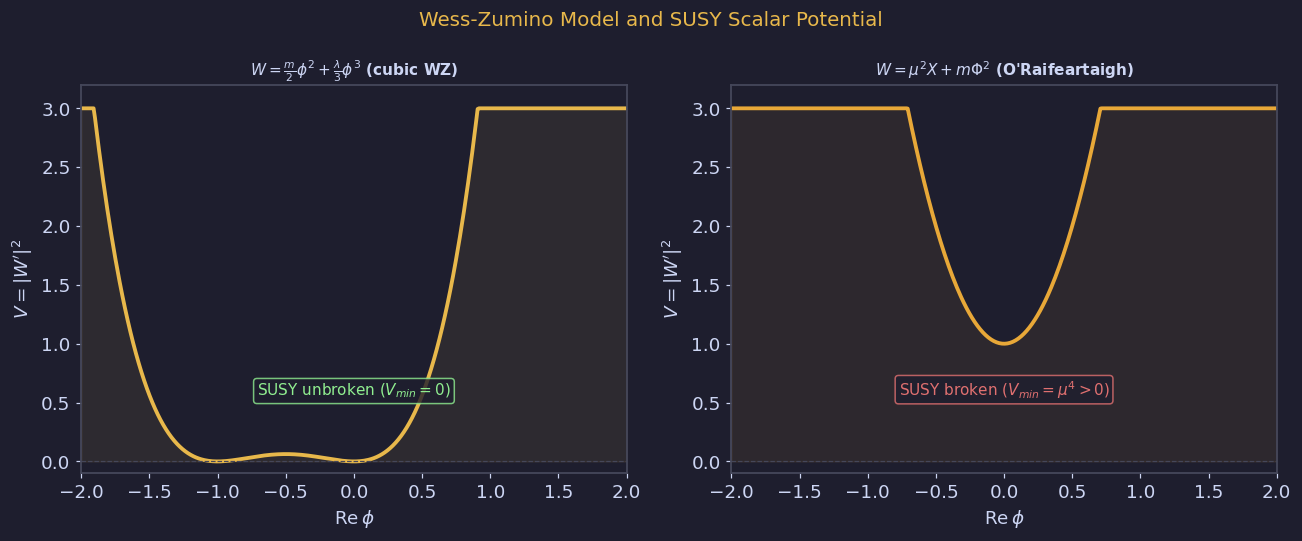

In [3]:
# Wess-Zumino model potential and SUSY breaking
fig, axes = plt.subplots(1,2,figsize=(12,5))
fig.suptitle('Wess-Zumino Model and SUSY Scalar Potential',color=GOLD,fontsize=13)
x=np.linspace(-2,2,400)

# V = |W'|^2 for W = m phi^2/2 + lambda phi^3/3
for ax_,W_label,Wp_fn,col_V in [
    (axes[0], r'$W=\frac{m}{2}\phi^2+\frac{\lambda}{3}\phi^3$ (cubic WZ)', lambda x: (1.0*x+x**2)**2, GOLD),
    (axes[1], r"$W=\mu^2 X + m\Phi^2$ (O'Raifeartaigh)", lambda x: 1.0 + 4.0 * x**2, ORAN),
]:
    V = Wp_fn(x)
    ax_.set_facecolor(BG)
    ax_.plot(x, np.clip(V,0,3), color=col_V, lw=2.5)
    ax_.fill_between(x, 0, np.clip(V,0,3), color=col_V, alpha=0.08)
    ax_.axhline(0,color=EDGE,lw=0.8,ls='--')
    ax_.set_xlabel(r'$\mathrm{Re}\,\phi$'); ax_.set_ylabel(r'$V=|W^\prime|^2$')
    ax_.set_title(W_label, color=FG, fontsize=10)
    ax_.set_ylim(-0.1,3.2); ax_.set_xlim(-2,2)
    min_V = np.min(V)
    status = r'SUSY unbroken ($V_{min}=0$)' if min_V < 0.01 else r'SUSY broken ($V_{min}=\mu^4>0$)'
    col_s = GREEN if min_V < 0.01 else RED
    ax_.text(0.5,0.2,status,ha='center',transform=ax_.transAxes,fontsize=10,
             color=col_s,bbox=dict(boxstyle='round,pad=0.22',fc=BG,ec=col_s,alpha=0.8))

plt.tight_layout()
save('fig02_wz_model.png',fig)


  saved -> figures/ch03/fig03_holomorphy.png


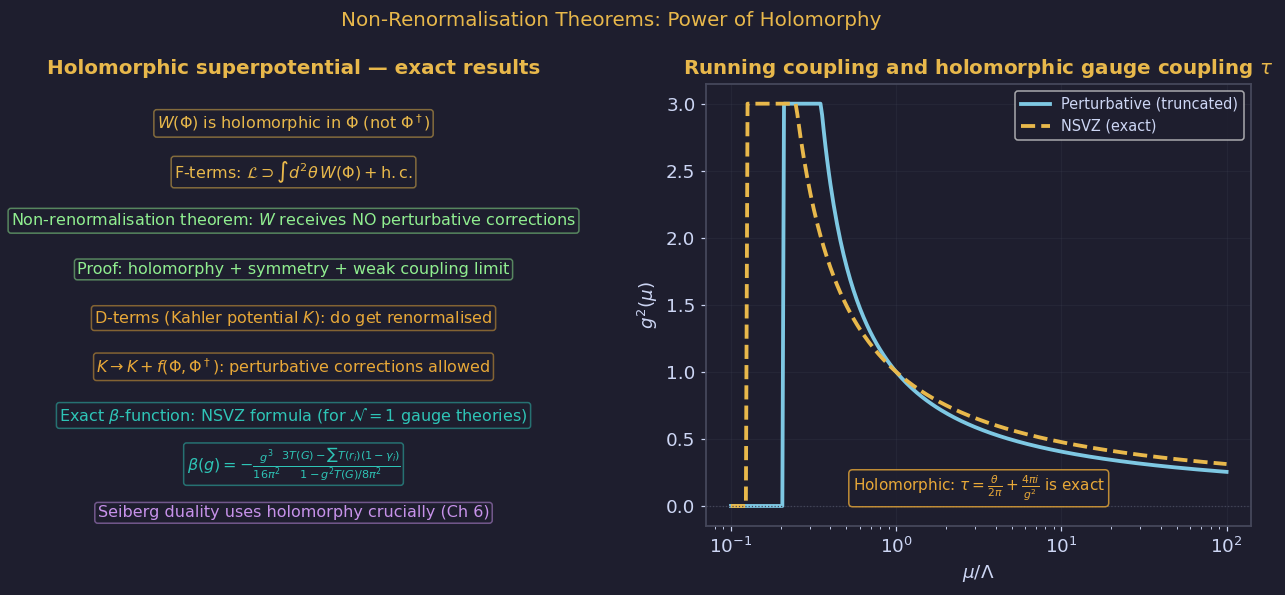

In [4]:
# Non-renormalisation and holomorphy
fig, axes = plt.subplots(1,2,figsize=(12,5.5))
fig.suptitle('Non-Renormalisation Theorems: Power of Holomorphy',color=GOLD,fontsize=13)

ax=axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title('Holomorphic superpotential — exact results',color=GOLD)
items=[
  (0.5,0.91,r'$W(\Phi)$ is holomorphic in $\Phi$ (not $\Phi^\dagger$)',GOLD),
  (0.5,0.80,r'F-terms: $\mathcal{L}\supset\int d^2\theta\,W(\Phi)+\mathrm{h.c.}$',GOLD),
  (0.5,0.69,r'Non-renormalisation theorem: $W$ receives NO perturbative corrections',GREEN),
  (0.5,0.58,r'Proof: holomorphy + symmetry + weak coupling limit',GREEN),
  (0.5,0.47,r'D-terms (Kahler potential $K$): do get renormalised',ORAN),
  (0.5,0.36,r'$K \to K + f(\Phi,\Phi^\dagger)$: perturbative corrections allowed',ORAN),
  (0.5,0.25,r'Exact $\beta$-function: NSVZ formula (for $\mathcal{N}=1$ gauge theories)',TEAL),
  (0.5,0.14,r'$\beta(g)=-\frac{g^3}{16\pi^2}\frac{3T(G)-\sum T(r_i)(1-\gamma_i)}{1-g^2T(G)/8\pi^2}$',TEAL),
  (0.5,0.03,r'Seiberg duality uses holomorphy crucially (Ch 6)',PURP),
]
for x_,y_,txt,col in items:
    ax.text(x_,y_,txt,ha='center',va='center',fontsize=10.5,color=col,
            transform=ax.transAxes,bbox=dict(boxstyle='round,pad=0.18',fc=BG,ec=col,alpha=0.5))

# Running coupling schematic
ax2=axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r'Running coupling and holomorphic gauge coupling $\tau$',color=GOLD)
mu=np.logspace(-1,2,300)
g2_perturbative = 1/(1+2*np.log(mu)/np.pi)
g2_exact = 1/(1+1.5*np.log(mu)/np.pi)
ax2.semilogx(mu, np.clip(g2_perturbative,0,3), color=BLUE, lw=2.5,
             label='Perturbative (truncated)')
ax2.semilogx(mu, np.clip(g2_exact,0,3), color=GOLD, lw=2.5, ls='--',
             label='NSVZ (exact)')
ax2.axhline(0,color=EDGE,lw=0.8,ls=':')
ax2.set_xlabel(r'$\mu/\Lambda$'); ax2.set_ylabel(r'$g^2(\mu)$')
ax2.legend(fontsize=9.5); ax2.grid(True,alpha=0.2)
ax2.text(0.5,0.08,r'Holomorphic: $\tau = \frac{\theta}{2\pi}+\frac{4\pi i}{g^2}$ is exact',
         ha='center',transform=ax2.transAxes,fontsize=10,color=ORAN,
         bbox=dict(boxstyle='round,pad=0.25',fc=BG,ec=ORAN,alpha=0.8))
plt.tight_layout()
save('fig03_holomorphy.png',fig)


  saved -> figures/ch03/fig04_susy_breaking.png


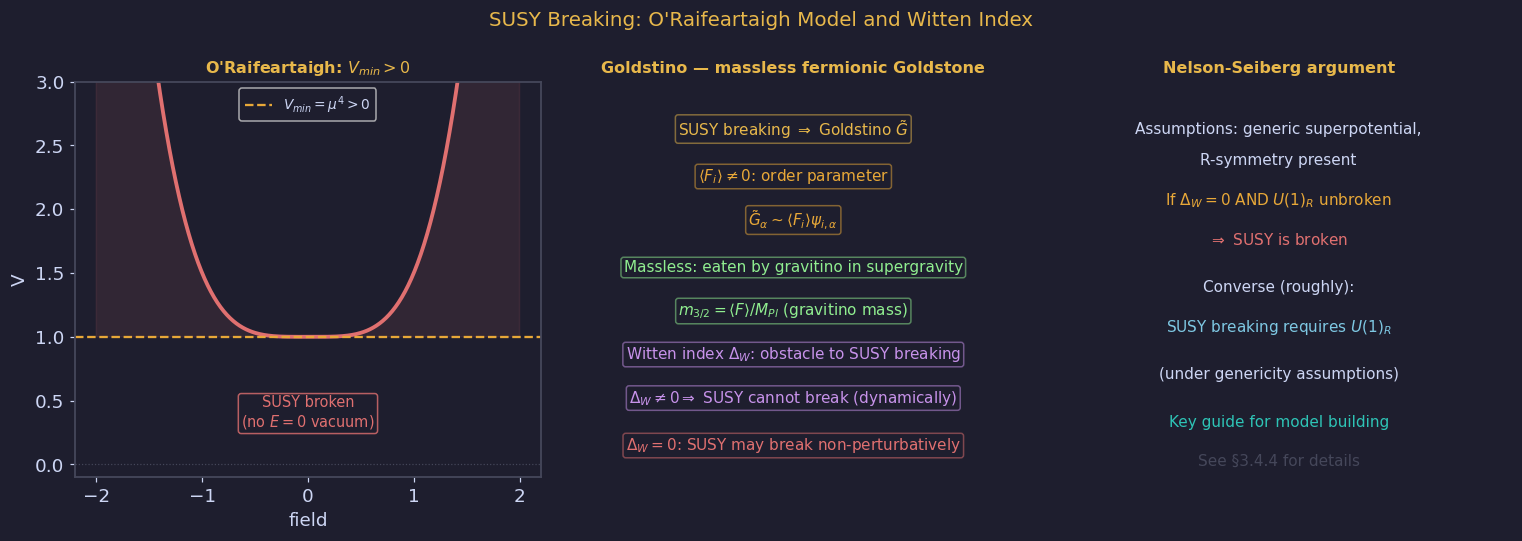

In [5]:
# SUSY breaking mechanisms
fig, axes = plt.subplots(1,3,figsize=(14,5))
fig.suptitle("SUSY Breaking: O'Raifeartaigh Model and Witten Index",color=GOLD,fontsize=13)

# ORaif model potential
x=np.linspace(-2,2,400)
V_OR = 1 + 0.5*(x**2)**2  # simplified: V = mu^4 + ...
ax=axes[0]; ax.set_facecolor(BG)
ax.set_title("O'Raifeartaigh: $V_{min}>0$",color=GOLD,fontsize=10.5)
ax.plot(x,V_OR,color=RED,lw=2.5)
ax.fill_between(x,1,V_OR,color=RED,alpha=0.10)
ax.axhline(1,color=ORAN,lw=1.5,ls='--',label=r'$V_{min}=\mu^4>0$')
ax.axhline(0,color=EDGE,lw=0.8,ls=':')
ax.set_xlabel(r'field'); ax.set_ylabel('V'); ax.legend(fontsize=9); ax.set_ylim(-0.1,3)
ax.text(0,0.3,'SUSY broken\n(no $E=0$ vacuum)',ha='center',fontsize=9.5,color=RED,
        bbox=dict(boxstyle='round,pad=0.2',fc=BG,ec=RED,alpha=0.8))

# Goldstino
ax2=axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title('Goldstino — massless fermionic Goldstone',color=GOLD,fontsize=10.5)
gold=[
  (0.5,0.88,r'SUSY breaking $\Rightarrow$ Goldstino $\tilde G$',GOLD),
  (0.5,0.76,r'$\langle F_i\rangle\neq 0$: order parameter',ORAN),
  (0.5,0.65,r'$\tilde G_\alpha \sim \langle F_i\rangle\psi_{i,\alpha}$',ORAN),
  (0.5,0.53,r'Massless: eaten by gravitino in supergravity',GREEN),
  (0.5,0.42,r'$m_{3/2} = \langle F\rangle/M_{Pl}$ (gravitino mass)',GREEN),
  (0.5,0.31,r'Witten index $\Delta_W$: obstacle to SUSY breaking',PURP),
  (0.5,0.20,r'$\Delta_W\neq 0 \Rightarrow$ SUSY cannot break (dynamically)',PURP),
  (0.5,0.08,r'$\Delta_W=0$: SUSY may break non-perturbatively',RED),
]
for x_,y_,txt,col in gold:
    ax2.text(x_,y_,txt,ha='center',va='center',fontsize=10,color=col,
             transform=ax2.transAxes,bbox=dict(boxstyle='round,pad=0.18',fc=BG,ec=col,alpha=0.5))

# Nelson-Seiberg
ax3=axes[2]; ax3.set_facecolor(BG); ax3.axis('off')
ax3.set_title('Nelson-Seiberg argument',color=GOLD,fontsize=10.5)
ns=[
  (0.5,0.88,'Assumptions: generic superpotential,',FG),
  (0.5,0.80,'R-symmetry present',FG),
  (0.5,0.70,r'If $\Delta_W=0$ AND $U(1)_R$ unbroken',ORAN),
  (0.5,0.60,r'$\Rightarrow$ SUSY is broken',RED),
  (0.5,0.48,'Converse (roughly):',FG),
  (0.5,0.38,r'SUSY breaking requires $U(1)_R$',BLUE),
  (0.5,0.26,'(under genericity assumptions)',FG),
  (0.5,0.14,'Key guide for model building',TEAL),
  (0.5,0.04,'See §3.4.4 for details',EDGE),
]
for x_,y_,txt,col in ns:
    ax3.text(x_,y_,txt,ha='center',va='center',fontsize=10,color=col,transform=ax3.transAxes)
plt.tight_layout()
save('fig04_susy_breaking.png',fig)


  saved -> figures/ch03/fig05_moduli_space.png


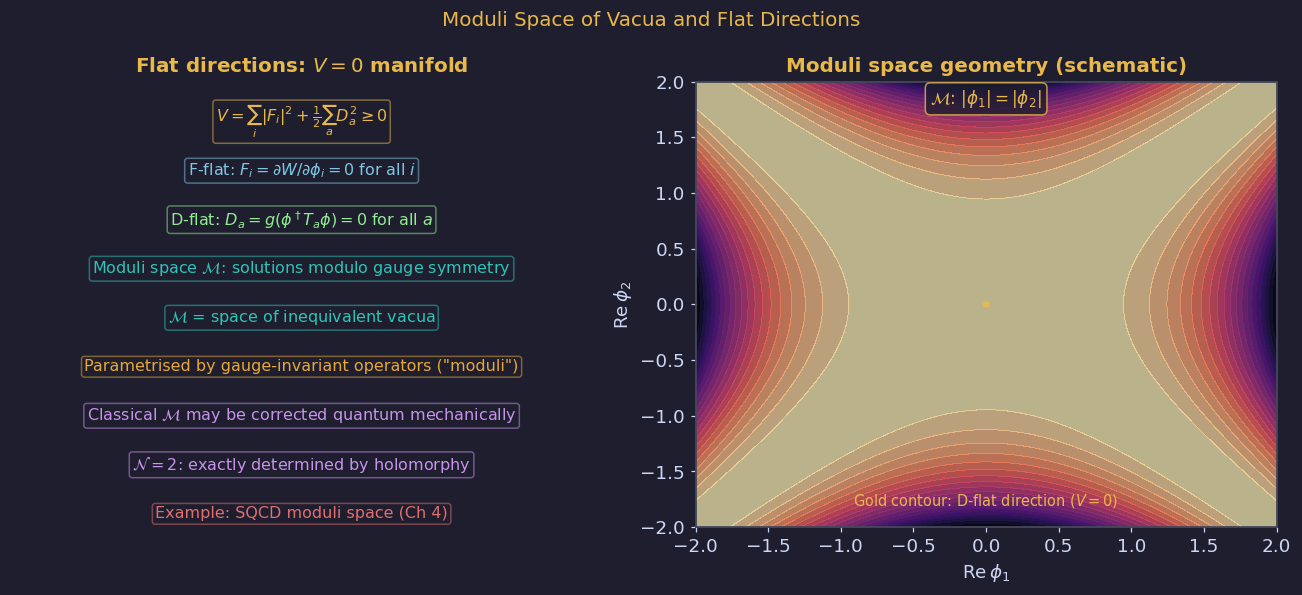

In [6]:
# Moduli space of vacua
fig, axes = plt.subplots(1,2,figsize=(12,5.5))
fig.suptitle('Moduli Space of Vacua and Flat Directions',color=GOLD,fontsize=13)

ax=axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title(r'Flat directions: $V=0$ manifold',color=GOLD)
items=[
  (0.5,0.91,r'$V = \sum_i|F_i|^2 + \frac{1}{2}\sum_a D_a^2 \geq 0$',GOLD),
  (0.5,0.80,r'F-flat: $F_i=\partial W/\partial\phi_i=0$ for all $i$',BLUE),
  (0.5,0.69,r'D-flat: $D_a=g(\phi^\dagger T_a\phi)=0$ for all $a$',GREEN),
  (0.5,0.58,r'Moduli space $\mathcal{M}$: solutions modulo gauge symmetry',TEAL),
  (0.5,0.47,r'$\mathcal{M}$ = space of inequivalent vacua',TEAL),
  (0.5,0.36,r'Parametrised by gauge-invariant operators ("moduli")',ORAN),
  (0.5,0.25,r'Classical $\mathcal{M}$ may be corrected quantum mechanically',PURP),
  (0.5,0.14,r'$\mathcal{N}=2$: exactly determined by holomorphy',PURP),
  (0.5,0.03,r'Example: SQCD moduli space (Ch 4)',RED),
]
for x_,y_,txt,col in items:
    ax.text(x_,y_,txt,ha='center',va='center',fontsize=10.5,color=col,
            transform=ax.transAxes,bbox=dict(boxstyle='round,pad=0.18',fc=BG,ec=col,alpha=0.5))

# Moduli space schematic — 2D projection
ax2=axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r'Moduli space geometry (schematic)',color=GOLD)
phi1=np.linspace(-2,2,300); phi2=np.linspace(-2,2,300)
P1,P2=np.meshgrid(phi1,phi2)
# Flat direction: |phi1|^2 = |phi2|^2 (D-flat for U(1))
V_flat = (np.abs(P1)**2 - np.abs(P2)**2)**2
ax2.contourf(P1,P2,V_flat,levels=20,cmap='magma_r',alpha=0.7)
ax2.contour(P1,P2,V_flat,levels=[0],colors=[GOLD],linewidths=3)
ax2.set_xlabel(r'$\mathrm{Re}\,\phi_1$'); ax2.set_ylabel(r'$\mathrm{Re}\,\phi_2$')
ax2.text(0,1.8,r'$\mathcal{M}$: $|\phi_1|=|\phi_2|$',ha='center',fontsize=11,color=GOLD,
         bbox=dict(boxstyle='round,pad=0.3',fc=BG,ec=GOLD,alpha=0.8))
ax2.text(0.5,0.05,'Gold contour: D-flat direction ($V=0$)',
         ha='center',transform=ax2.transAxes,fontsize=9.5,color=GOLD)
plt.tight_layout()
save('fig05_moduli_space.png',fig)


In [7]:
import shutil
shutil.make_archive('susyft_ch03_figures','zip','figures/ch03')
try:
    from google.colab import files; files.download('susyft_ch03_figures.zip')
except ImportError:
    print('figures saved to figures/ch03/')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>